In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "archive.zip":
            print(os.path.join(root, file))

/content/drive/MyDrive/archive.zip


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'chest_xray', 'drive', 'sample_data']


In [ ]:
import os

print("Dataset folders:")
print(os.listdir("/content/chest_xray"))

Dataset folders:
['__MACOSX', 'chest_xray', 'train', 'test', 'val']


In [ ]:
import os

print("Train:", os.listdir("/content/chest_xray/train"))
print("Test:", os.listdir("/content/chest_xray/test"))
print("Validation:", os.listdir("/content/chest_xray/val"))

Train: ['PNEUMONIA', 'NORMAL']
Test: ['PNEUMONIA', 'NORMAL']
Validation: ['PNEUMONIA', 'NORMAL']


In [ ]:
import tensorflow as tf

train_data = tf.keras.utils.image_dataset_from_directory(
    "/content/chest_xray/train",
    image_size=(150, 150),
    batch_size=32
)

print("Classes:", train_data.class_names)

Found 5216 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
val_data = tf.keras.utils.image_dataset_from_directory(
    "/content/chest_xray/val",
    image_size=(150, 150),
    batch_size=32
)

print("Validation classes:", val_data.class_names)

Found 16 files belonging to 2 classes.
Validation classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
test_data = tf.keras.utils.image_dataset_from_directory(
    "/content/chest_xray/test",
    image_size=(150, 150),
    batch_size=32,
    shuffle=False
)

print("Test classes:", test_data.class_names)

Found 624 files belonging to 2 classes.
Test classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
print("Training classes:", train_data.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_data).numpy())

Training classes: ['NORMAL', 'PNEUMONIA']
Training batches: 163


In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(150, 150, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,636,481 (40.57 MB)

 Trainable params: 10,636,481 (40.57 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.9195 - loss: 0.2461 - val_accuracy: 0.6875 - val_loss: 0.5591
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.9651 - loss: 0.0942 - val_accuracy: 0.8750 - val_loss: 0.1639
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 288s 2s/step - accuracy: 0.9814 - loss: 0.0530 - val_accuracy: 0.9375 - val_loss: 0.0918
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9862 - loss: 0.0407 - val_accuracy: 0.7500 - val_loss: 0.6753
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 250s 2s/step - accuracy: 0.9829 - loss: 0.0441 - val_accuracy: 0.8750 - val_loss: 0.2550


In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("CNN Test Loss:", test_loss)
print("CNN Test Accuracy:", test_accuracy)

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 438ms/step - accuracy: 0.7452 - loss: 1.4643
CNN Test Loss: 1.4643146991729736
CNN Test Accuracy: 0.745192289352417


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Get predictions
predictions = model.predict(test_data)

# Convert probabilities to class labels
predicted_classes = (predictions > 0.5).astype(int).flatten()

# Get actual labels
actual_classes = np.concatenate(
    [y for x, y in test_data],
    axis=0
)

# Confusion Matrix
cm = confusion_matrix(actual_classes, predicted_classes)

print("Confusion Matrix:")
print(cm)

print("Classification Report:")

print(
    classification_report(
        actual_classes,
        predicted_classes,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 607ms/step
Confusion Matrix:
[[ 78 156]
 [  3 387]]
Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.96      0.33      0.50       234
   PNEUMONIA       0.71      0.99      0.83       390

    accuracy                           0.75       624
   macro avg       0.84      0.66      0.66       624
weighted avg       0.81      0.75      0.70       624



In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

/tmp/ipykernel_3851/4292231764.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [ ]:
model_tl = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model_tl.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_tl.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history_tl = model_tl.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 146s 844ms/step - accuracy: 0.9026 - loss: 0.2258 - val_accuracy: 0.7500 - val_loss: 0.7502
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 137s 839ms/step - accuracy: 0.9298 - loss: 0.1710 - val_accuracy: 0.8125 - val_loss: 0.6793
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 143s 846ms/step - accuracy: 0.9473 - loss: 0.1366 - val_accuracy: 0.6875 - val_loss: 1.1440
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 148s 886ms/step - accuracy: 0.9546 - loss: 0.1175 - val_accuracy: 0.7500 - val_loss: 0.9180
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 138s 846ms/step - accuracy: 0.9605 - loss: 0.1041 - val_accuracy: 0.7500 - val_loss: 1.1698


In [ ]:
test_loss_tl, test_accuracy_tl = model_tl.evaluate(test_data)

print("MobileNetV2 Test Loss:", test_loss_tl)
print("MobileNetV2 Test Accuracy:", test_accuracy_tl)


20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7228 - loss: 0.8750
MobileNetV2 Test Loss: 0.8750314116477966
MobileNetV2 Test Accuracy: 0.7227563858032227


In [ ]:
predictions_tl = model_tl.predict(test_data)

predicted_classes_tl = (
    predictions_tl > 0.5
).astype(int).flatten()

actual_classes_tl = np.concatenate(
    [y for x, y in test_data],
    axis=0
)

cm_tl = confusion_matrix(
    actual_classes_tl,
    predicted_classes_tl
)

print("MobileNetV2 Confusion Matrix:")
print(cm_tl)

print("MobileNetV2 Classification Report:")

print(
    classification_report(
        actual_classes_tl,
        predicted_classes_tl,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 805ms/step
MobileNetV2 Confusion Matrix:
[[ 63 171]
 [  2 388]]
MobileNetV2 Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.97      0.27      0.42       234
   PNEUMONIA       0.69      0.99      0.82       390

    accuracy                           0.72       624
   macro avg       0.83      0.63      0.62       624
weighted avg       0.80      0.72      0.67       624



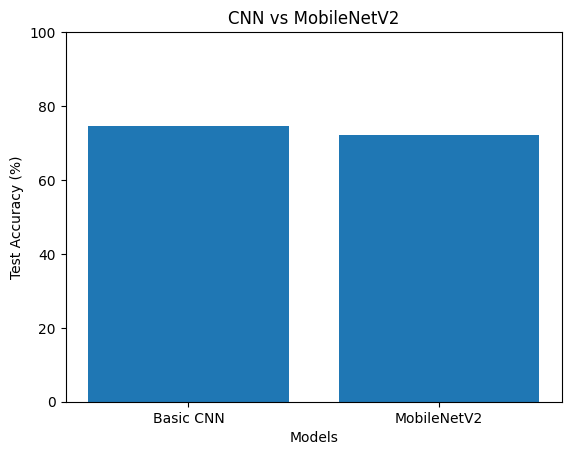

In [ ]:
import matplotlib.pyplot as plt

models = ["Basic CNN", "MobileNetV2"]
accuracies = [74.52, 72.28]

plt.bar(models, accuracies)

plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs MobileNetV2")

plt.ylim(0, 100)

plt.show()

In [ ]:
model_tl.save("/content/mobilenet_pneumonia_colab.keras")

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [ ]:
model_tl.save("/content/mobilenet_pneumonia_colab.keras")

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [ ]:
model.save("/content/drive/MyDrive/basic_cnn_pneumonia.keras")

model_tl.save("/content/drive/MyDrive/mobilenet_pneumonia_colab.keras")

print("Both models saved to Google Drive!")

Both models saved to Google Drive!


In [ ]:
import os

print(os.path.exists("/content/sample.jpeg"))

False


In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import os

normal_folder = "/content/chest_xray/test/NORMAL"

normal_images = os.listdir(normal_folder)

print("Number of NORMAL images:", len(normal_images))
print("First image:", normal_images[0])

Number of NORMAL images: 234
First image: NORMAL2-IM-0198-0001.jpeg


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Model Prediction: PNEUMONIA


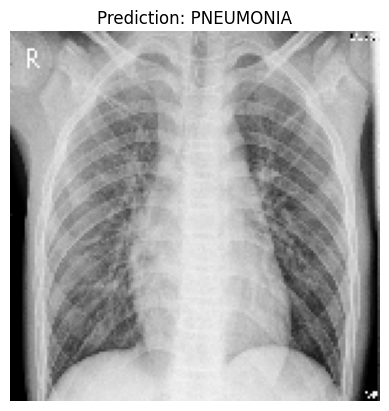

In [ ]:
img_path = "/content/chest_xray/test/NORMAL/NORMAL2-IM-0198-0001.jpeg"

img = tf.keras.utils.load_img(
    img_path,
    target_size=(150, 150)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

prediction = model_tl.predict(img_array)

if prediction[0][0] > 0.5:
    result = "PNEUMONIA"
else:
    result = "NORMAL"

print("Model Prediction:", result)

plt.imshow(img)
plt.axis("off")
plt.title("Prediction: " + result)
plt.show()

In [ ]:
pneumonia_folder = "/content/chest_xray/test/PNEUMONIA"

pneumonia_images = os.listdir(pneumonia_folder)

print("Number of PNEUMONIA images:", len(pneumonia_images))
print("First image:", pneumonia_images[0])

Number of PNEUMONIA images: 390
First image: person1619_virus_2806.jpeg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
Actual Label: PNEUMONIA
Model Prediction: PNEUMONIA


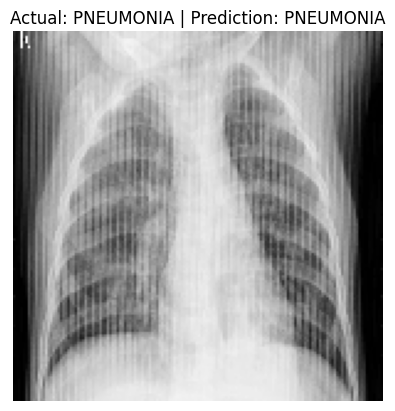

In [ ]:
img_path = "/content/chest_xray/test/PNEUMONIA/person1619_virus_2806.jpeg"

img = tf.keras.utils.load_img(
    img_path,
    target_size=(150, 150)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

prediction = model_tl.predict(img_array)

if prediction[0][0] > 0.5:
    result = "PNEUMONIA"
else:
    result = "NORMAL"

print("Actual Label: PNEUMONIA")
print("Model Prediction:", result)

plt.imshow(img)
plt.axis("off")
plt.title("Actual: PNEUMONIA | Prediction: " + result)
plt.show()

In [ ]:
print("PNEUMONIA DETECTION PROJECT")
print()
print("Basic CNN Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("MobileNetV2 Test Accuracy:",
      round(test_accuracy_tl * 100, 2), "%")

print()
print("Sample 1")
print("Actual: NORMAL")
print("Prediction: PNEUMONIA")

print()
print("Sample 2")
print("Actual: PNEUMONIA")
print("Prediction: PNEUMONIA")

PNEUMONIA DETECTION PROJECT

Basic CNN Test Accuracy: 74.52 %
MobileNetV2 Test Accuracy: 72.28 %

Sample 1
Actual: NORMAL
Prediction: PNEUMONIA

Sample 2
Actual: PNEUMONIA
Prediction: PNEUMONIA


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sample.jpeg to sample.jpeg


In [ ]:
import os

image_name = list(uploaded.keys())[0]
image_path = "/content/" + image_name

print("Image uploaded:", image_name)

Image uploaded: sample.jpeg


In [ ]:
img = tf.keras.utils.load_img(
    image_path,
    target_size=(150, 150)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

prediction = model_tl.predict(img_array)

score = prediction[0][0]

if score > 0.5:
    result = "PNEUMONIA"
else:
    result = "NORMAL"

print("Model Prediction:", result)
print("Prediction Score:", round(float(score), 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Model Prediction: PNEUMONIA
Prediction Score: 0.9992


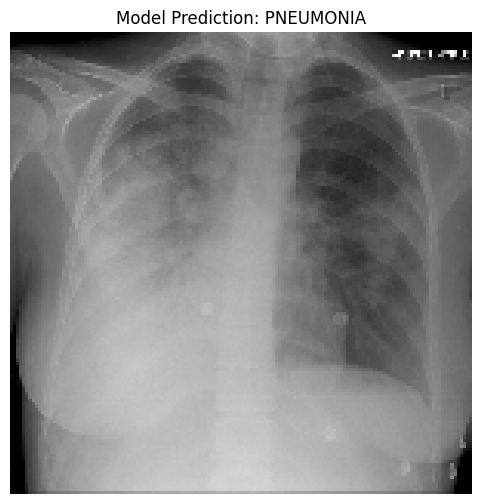

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(img)
plt.axis("off")
plt.title("Model Prediction: " + result)

plt.show()